# EDA картинок: насколько CLIP-эмбеддинги различают товары

Вопрос: если картинки товаров в эмбеддингах CLIP в основном похожи друг на друга, модель не сможет по ним отличать товары. Смотрим на геометрию эмбеддингов, без модели рекомендаций:

1. распределение косинусных сходств случайных пар товаров;
2. эффективная размерность (PCA);
3. почти-дубликаты;
4. различимость конкретного товара: находится ли по главной картинке вторая картинка того же товара;
5. смысловая структура: соседи по картинке того же типа товара или магазина;
6. хабы: товары, которые оказываются соседями почти у всех;
7. всё это по бакетам холодности из `eda_coldness`;
8. то же для эмбеддингов названий (текстовый энкодер того же CLIP) как точка сравнения;
9. похожесть товаров внутри истории юзера по сравнению со случайными историями той же популярности.

Модель: CLIP ViT-B/32 (`laion2b_s34b_b79k`, open_clip). Картинки `large` (~500 px): CLIP всё равно уменьшает их до 224 px. Эмбеддинги кешируются в `data/cache/clip/`, повторный запуск ничего не скачивает.

Выборка на категорию: до 2000 товаров с картинкой из каждого бакета холодности на дату `CUTOFF`, плюс истории 3000 юзеров с 2+ товарами за 24 месяца до `CUTOFF`.

In [1]:
import truststore

# до импорта s3fs и boto3, иначе ssl уходит в бесконечную рекурсию
truststore.inject_into_ssl()

In [2]:
import io
from pathlib import Path
from typing import Any, cast

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import umap
from IPython.display import display
from PIL import Image
from scipy.stats import skew

from recsys.data.load import (
    cache_dir,
    fetch_image,
    fetch_images,
    image_urls,
    read_meta,
    read_reviews,
)

In [3]:
CUTOFF = pd.Timestamp("2022-01-01")
CATEGORIES = ["Amazon_Fashion", "Grocery_and_Gourmet_Food"]

# бакеты товаров как в eda_coldness: число юзеров товара в train
ITEM_BINS = [-1, 0, 1, 4, 19, float("inf")]
ITEM_LABELS = ["0", "1", "2-4", "5-19", "20+"]

ITEMS_PER_BUCKET = 2000
WINDOW_MONTHS = 24  # окно истории юзеров перед CUTOFF
N_USERS = 3000
MAX_HISTORY = 50  # последние товары юзера, чтобы длинные истории не задавили остальных
N_INSTANCE = 2000  # товаров для проверки MAIN -> PT01
K = 10  # соседей
NEAR_DUP = 0.95  # косинус (без центрирования), выше которого картинки почти одинаковые
MIN_LABEL = 30  # меньше товаров с меткой в выборке: метку не учитываем
MIN_STORE = 5
SEED = 0

MODEL, PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"
rng = np.random.default_rng(SEED)
print(DEVICE)

mps


## Метки товаров

Чтобы проверить смысловую структуру, нужны метки. У Grocery есть путь категорий, берём уровень 1 (Pantry Staples, Snacks & Sweets, Beverages, ...). У Fashion `categories` пустые у всех товаров. Тип товара проставлен по названию моделью Claude Haiku 5.5 (`scripts/label_fashion_types.py`, метки в `reports/fashion_item_types.csv`). Список из 26 типов собран по каталогу Amazon: в Clothing_Shoes_and_Jewelry лежат такие же товары (main_category = AMAZON FASHION) с путём категорий, но других `parent_asin`, пересечения с Fashion почти нет. На 2 500 товарах Clothing, где тип известен по пути каталога, модель угадывает тип у 87.5% товаров. По 14 классам прежних правил по ключевым словам: 91.6% у модели против 80.0% у правил, а правила к тому же ставили метку 40% товаров тех типов, для которых у них нет класса. Тип `other` (не одежда и не аксессуары, 2.5% выборки) в метки не берём.

Важно: метки Fashion получены из названий, поэтому сравнение чистоты по картинкам и по названиям у Fashion смещено в пользу названий. У Grocery метки из каталога, этого смещения нет.

In [4]:
# типы Fashion размечены LLM по названиям, см. markdown выше
FASHION_TYPES = pd.read_csv(
    "../reports/fashion_item_types.csv", index_col="parent_asin"
)["llm_type"]


def fashion_type(asins):
    label = asins.map(FASHION_TYPES).astype("string")
    return label.mask(label == "other")  # не одежда: без метки


def grocery_type(categories, level=1):
    """Уровень пути каталога: 1 — Beverages, Snacks & Sweets; 2 — Coffee, Tea."""
    label = categories.map(
        lambda c: c[level] if c is not None and len(c) > level else None
    )
    return label.astype("string")

## Загрузка

Отзывы до `CUTOFF` нужны для бакетов (сколько юзеров у товара в train) и для историй. Метаданные читаются из локального кеша.

In [5]:
def load_category(category):
    reviews = read_reviews(
        category,
        columns=["user_id", "parent_asin", "timestamp"],
        years=range(1990, CUTOFF.year + 1),
    )
    train = reviews[reviews["timestamp"] < CUTOFF]
    n_users = (
        train.drop_duplicates(["user_id", "parent_asin"]).groupby("parent_asin").size()
    )
    start = CUTOFF - pd.DateOffset(months=WINDOW_MONTHS)
    window = train[train["timestamp"] >= start].reset_index(drop=True)
    del reviews, train

    columns = ["parent_asin", "title", "store", "categories", "images"]
    meta = read_meta(category, columns=columns).drop_duplicates("parent_asin")
    urls = image_urls(meta, size="large").drop_duplicates(["parent_asin", "variant"])
    variants = urls.pivot(index="parent_asin", columns="variant", values="url")

    if category == "Amazon_Fashion":
        label = fashion_type(meta["parent_asin"])
        label2 = pd.Series(pd.NA, index=meta.index, dtype="string")
    else:
        label = grocery_type(meta["categories"])
        label2 = grocery_type(meta["categories"], level=2)
    items = pd.DataFrame(
        {
            "title": meta["title"].to_numpy(),
            "store": meta["store"].to_numpy(),
            "label": label.to_numpy(),
            "label2": label2.to_numpy(),
        },
        index=pd.Index(meta["parent_asin"], name="parent_asin"),
    )
    items["n_users"] = n_users.reindex(items.index).fillna(0).astype(int)
    items["bucket"] = pd.cut(items["n_users"], bins=ITEM_BINS, labels=ITEM_LABELS)
    variants = variants.reindex(index=items.index, columns=["MAIN", "PT01"])
    items["main"] = variants["MAIN"]
    items["pt01"] = variants["PT01"]

    main = items["main"].dropna()
    print(
        f"{category}: товаров {len(items):,}, с картинкой MAIN {len(main):,}, "
        f"с PT01 {items['pt01'].notna().sum():,}; "
        f"картинка MAIN общая с другим товаром у "
        f"{main.duplicated(keep=False).mean():.2%}"
    )
    # у Fashion размечена только выборка, поэтому доля по каталогу маленькая
    print(f"  с меткой: {items['label'].notna().mean():.1%} каталога")
    display(items["label"].value_counts().head(15).to_frame().T)
    return items, window

## Выборка

Товары: до `ITEMS_PER_BUCKET` с картинкой из каждого бакета. Юзеры: случайные `N_USERS` из тех, у кого за окно 2+ разных товара с картинкой; от длинных историй берём последние `MAX_HISTORY` товаров.

Базовая линия для историй: каждому юзеру те же длина и порядок, но товары случайные, выбранные пропорционально числу взаимодействий в окне. Так случайная история так же смещена к популярным товарам, как настоящая, и разница с ней получается из-за вкуса юзера, а не из-за популярности.

In [6]:
def sample_items(items):
    with_image = items[items["main"].notna()]
    parts = [
        group.sample(min(len(group), ITEMS_PER_BUCKET), random_state=SEED)
        for _, group in with_image.groupby("bucket", observed=True)
    ]
    return pd.concat(parts).index


def sample_histories(window, items):
    with_image = items.index[items["main"].notna()]
    window = window[window["parent_asin"].isin(with_image)]
    hist = window.sort_values("timestamp").drop_duplicates(["user_id", "parent_asin"])
    size = hist.groupby("user_id").size()
    eligible = size.index[size >= 2].to_numpy()
    users = rng.choice(eligible, size=min(N_USERS, len(eligible)), replace=False)
    hist = hist[hist["user_id"].isin(users)].groupby("user_id").tail(MAX_HISTORY)
    pool = window["parent_asin"].to_numpy()  # одна строка на взаимодействие
    fake = hist.assign(parent_asin=rng.choice(pool, size=len(hist)))
    fake = fake.drop_duplicates(["user_id", "parent_asin"])
    print(
        f"  юзеров с 2+ товарами в окне {len(eligible):,}, взяли {len(users):,}, "
        f"товаров в их историях {hist['parent_asin'].nunique():,}, "
        f"медиана длины {hist.groupby('user_id').size().median():.0f}"
    )
    return hist.reset_index(drop=True), fake.reset_index(drop=True)

## Эмбеддинги

In [7]:
clip_model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL, pretrained=PRETRAINED, device=DEVICE
)
# open_clip типизирует модель как nn.Module, на деле это CLIP
model = cast(open_clip.CLIP, clip_model)
model.eval()
tokenizer = open_clip.get_tokenizer(MODEL)
EMB_DIR = cache_dir() / "clip" / f"{MODEL}_{PRETRAINED}"


def decode(data):
    try:
        return preprocess(Image.open(io.BytesIO(data)).convert("RGB"))
    except Exception:  # битый или неподдерживаемый файл
        return None


def load_cache(path):
    if not path.exists():
        return {}
    saved = np.load(path)
    return dict(zip(saved["urls"].tolist(), saved["emb"], strict=True))


def save_cache(path, done):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f"{path.stem}.part.npz")
    np.savez(tmp, urls=np.array(list(done)), emb=np.stack(list(done.values())))
    tmp.replace(path)


@torch.no_grad()
def embed_images(urls, name, chunk=1024, batch=256):
    path = EMB_DIR / f"{name}.npz"
    done = load_cache(path)
    todo = [u for u in dict.fromkeys(urls) if u not in done]
    failed = 0
    for start in range(0, len(todo), chunk):
        tensors, ok = [], []
        for url, data in fetch_images(todo[start : start + chunk], workers=32).items():
            tensor = decode(data) if data else None
            if tensor is None:
                failed += 1
                continue
            tensors.append(tensor)
            ok.append(url)
        for b in range(0, len(ok), batch):
            emb = model.encode_image(torch.stack(tensors[b : b + batch]).to(DEVICE))
            emb = torch.nn.functional.normalize(emb.float(), dim=-1).cpu().numpy()
            done.update(zip(ok[b : b + batch], emb.astype(np.float16), strict=True))
        save_cache(path, done)
    print(
        f"  картинок {len(set(urls)):,}, посчитано сейчас {len(todo) - failed:,}, "
        f"не скачалось {failed:,}"
    )
    return done


@torch.no_grad()
def embed_texts(texts, batch=512):
    out = []
    for b in range(0, len(texts), batch):
        tokens = cast(torch.Tensor, tokenizer(texts[b : b + batch])).to(DEVICE)
        emb = model.encode_text(tokens).float()
        out.append(torch.nn.functional.normalize(emb, dim=-1).cpu().numpy())
    return np.concatenate(out)


def to_frame(urls, done):
    urls = urls[urls.isin(done.keys())]
    matrix = np.stack([done[u] for u in urls]).astype(np.float32)
    return pd.DataFrame(matrix, index=urls.index)


def normalize(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)


def centered(frame, mean):
    return pd.DataFrame(normalize(frame.to_numpy() - mean), index=frame.index)

**Центрирование.** Эмбеддинги CLIP лежат в узком конусе: даже у совсем разных картинок косинус обычно 0.3–0.6, и «сырой» косинус плохо показывает, насколько картинки различаются. Поэтому почти везде вычитаем средний эмбеддинг выборки товаров категории и нормируем заново. Тогда у случайной пары косинус около 0, и видно, насколько пара ближе или дальше среднего. Порог почти-дубликатов считаем по сырому косинусу: там он означает почти одинаковую картинку.

In [8]:
def build(category) -> dict[str, Any]:
    items, window = load_category(category)
    sample = sample_items(items)
    hist, fake = sample_histories(window, items)
    with_pt01 = sample[items.loc[sample, "pt01"].notna().to_numpy()]
    instance = pd.Index(
        rng.choice(with_pt01, size=min(N_INSTANCE, len(with_pt01)), replace=False)
    )

    # union сохраняет повторы из входов, а один товар бывает у многих юзеров
    ids = pd.concat([hist["parent_asin"], fake["parent_asin"]]).unique()
    asins = sample.union(pd.Index(ids, dtype=items.index.dtype))
    assert asins.is_unique
    name = category.lower()
    done = embed_images(
        pd.concat([items.loc[asins, "main"], items.loc[instance, "pt01"]]).tolist(),
        name,
    )
    img = to_frame(items.loc[asins, "main"], done)
    pt01 = to_frame(items.loc[instance, "pt01"], done)

    titles = items.loc[asins, "title"].fillna("").str.strip()
    titles = titles[titles != ""]
    txt = pd.DataFrame(embed_texts(titles.tolist()), index=titles.index)

    sample = sample.intersection(img.index)
    img_mean = img.loc[sample].to_numpy().mean(axis=0)
    txt_mean = txt.loc[sample.intersection(txt.index)].to_numpy().mean(axis=0)
    return {
        "items": items.loc[asins.union(instance)],
        "sample": sample,
        "instance": instance.intersection(img.index).intersection(pt01.index),
        "hist": hist,
        "fake": fake,
        "image": img,
        "text": txt,
        "image_c": centered(img, img_mean),
        "pt01_c": centered(pt01, img_mean),
        "text_c": centered(txt, txt_mean),
    }


R: dict[str, dict[str, Any]] = {}
for category in CATEGORIES:
    R[category] = build(category)

Amazon_Fashion: товаров 826,108, с картинкой MAIN 810,540, с PT01 675,739; картинка MAIN общая с другим товаром у 32.22%
  с меткой: 1.2% каталога


label,jewelry,dresses,tops,shoes,bags_wallets,pants,other_accessories,eyewear,sweaters_hoodies,hats,underwear,socks_hosiery,sleepwear,swimwear,watch_bands
count,1668,1110,1103,548,489,441,414,383,357,344,283,265,257,255,250


  юзеров с 2+ товарами в окне 36,161, взяли 3,000, товаров в их историях 7,102, медиана длины 2
  картинок 24,523, посчитано сейчас 0, не скачалось 0


Grocery_and_Gourmet_Food: товаров 603,274, с картинкой MAIN 600,928, с PT01 394,851; картинка MAIN общая с другим товаром у 9.01%
  с меткой: 88.7% каталога


label,Pantry Staples,Snacks & Sweets,Beverages,Breads & Bakery,"Dairy, Eggs & Plant-Based Alternatives",Produce,Food & Beverage Gifts,Frozen,Meat & Seafood,Deli & Prepared Foods,Breakfast Foods,Fresh Flowers & Live Indoor Plants,"Canned, Packaged & Baking",Breakfast Cereal,Alcoholic Beverages
count,210135,109105,95811,25033,11951,11777,11444,9185,9179,7048,6662,4273,3976,3534,2682


  юзеров с 2+ товарами в окне 705,097, взяли 3,000, товаров в их историях 8,151, медиана длины 2
  картинок 25,993, посчитано сейчас 0, не скачалось 0


## Общие функции

In [9]:
def knn(query, gallery, k, same=False, block=4096):
    """k ближайших по косинусу (векторы нормированы). same=True: query и gallery
    одна матрица, сам себе не сосед."""
    q = torch.from_numpy(np.ascontiguousarray(query, dtype=np.float32)).to(DEVICE)
    g = torch.from_numpy(np.ascontiguousarray(gallery, dtype=np.float32)).to(DEVICE)
    sims, idx = [], []
    for start in range(0, len(q), block):
        s = q[start : start + block] @ g.T
        if same:
            rows = torch.arange(len(s), device=DEVICE)
            s[rows, rows + start] = -2.0
        v, i = s.topk(k, dim=1)
        sims.append(v.cpu().numpy())
        idx.append(i.cpu().numpy())
    return np.concatenate(sims), np.concatenate(idx)


def random_pair_sims(x, n=200_000):
    a = rng.integers(0, len(x), n)
    b = rng.integers(0, len(x), n)
    keep = a != b
    return np.einsum("ij,ij->i", x[a[keep]], x[b[keep]])


def describe(values):
    q = np.nanquantile(values, [0.05, 0.25, 0.5, 0.75, 0.95])
    return pd.Series(
        {
            "mean": np.nanmean(values),
            "std": np.nanstd(values),
            "p5": q[0],
            "p25": q[1],
            "p50": q[2],
            "p75": q[3],
            "p95": q[4],
        }
    ).round(3)


def show_images(rows, captions=None, size=1.7):
    """Сетка картинок: rows — список строк с URL."""
    ncols = max(len(r) for r in rows)
    fig, axes = plt.subplots(
        len(rows), ncols, figsize=(ncols * size, len(rows) * size), squeeze=False
    )
    for ax in axes.flat:
        ax.axis("off")
    for i, row in enumerate(rows):
        for j, url in enumerate(row):
            try:
                axes[i, j].imshow(
                    Image.open(io.BytesIO(fetch_image(url))).convert("RGB")
                )
            except Exception:
                continue
            if captions is not None:
                axes[i, j].set_title(captions[i][j], fontsize=7)
    plt.tight_layout()
    plt.show()


def matrix(r, space, index):
    frame = r[space]
    return frame.loc[index.intersection(frame.index)].to_numpy()

## 1. Сходство случайных пар

Если у случайных пар товаров сходство высокое и разброс маленький, картинки слабо различаются. Сравниваем сырой и центрированный косинус, картинки и названия.

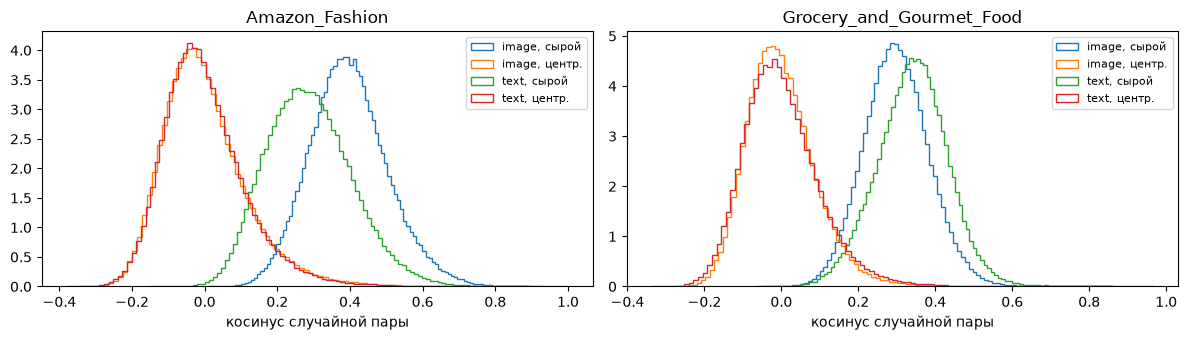

mean    std     p5    p25    p50  \
Amazon_Fashion           image сырой   0.396  0.107  0.227  0.323  0.392   
                               центр.  0.001  0.116 -0.158 -0.079 -0.015   
                         text  сырой   0.287  0.118  0.108  0.203  0.281   
                               центр. -0.000  0.114 -0.158 -0.078 -0.014   
Grocery_and_Gourmet_Food image сырой   0.298  0.085  0.163  0.241  0.297   
                               центр. -0.000  0.090 -0.129 -0.063 -0.009   
                         text  сырой   0.340  0.092  0.186  0.281  0.342   
                               центр. -0.000  0.099 -0.142 -0.068 -0.010   

                                         p75    p95  
Amazon_Fashion           image сырой   0.463  0.584  
                               центр.  0.062  0.216  
                         text  сырой   0.363  0.492  
                               центр.  0.061  0.206  
Grocery_and_Gourmet_Food image сырой   0.353  0.440  
                               центр.  0.051  0.157  
                         text  сырой   0.400  0.486  
                               центр.  0.056  0.174

In [10]:
rows = {}
fig, axes = plt.subplots(1, len(R), figsize=(6 * len(R), 3.5), squeeze=False)
for ax, (category, r) in zip(axes[0], R.items(), strict=True):
    for space, cen in [("image", "image_c"), ("text", "text_c")]:
        raw_sims = random_pair_sims(matrix(r, space, r["sample"]))
        cen_sims = random_pair_sims(matrix(r, cen, r["sample"]))
        rows[(category, space, "сырой")] = describe(raw_sims)
        rows[(category, space, "центр.")] = describe(cen_sims)
        ax.hist(
            raw_sims, bins=100, histtype="step", density=True, label=f"{space}, сырой"
        )
        ax.hist(
            cen_sims, bins=100, histtype="step", density=True, label=f"{space}, центр."
        )
    ax.set_title(category)
    ax.set_xlabel("косинус случайной пары")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pair_table = pd.DataFrame(rows).T
pair_table

## 2. Эффективная размерность

Сколько главных компонент объясняют 50/80/90/95% дисперсии эмбеддингов из 512, и participation ratio: (Σλ)² / Σλ². Если почти вся дисперсия в нескольких направлениях, товары различаются по немногим признакам.

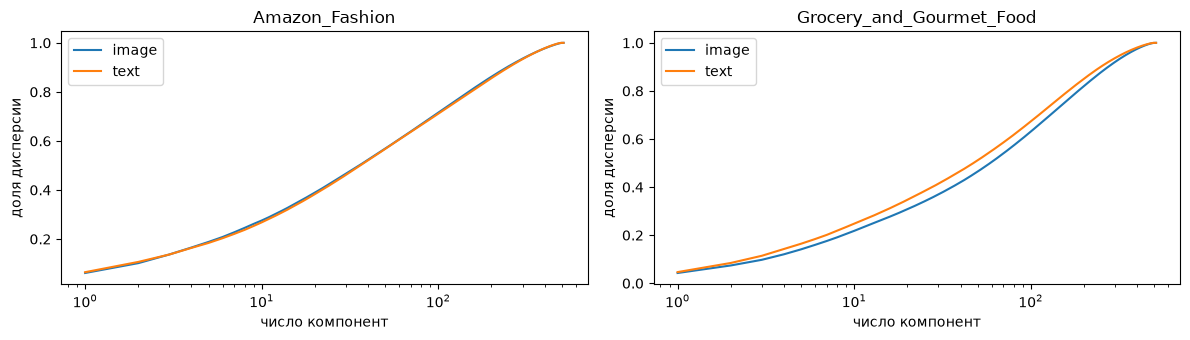

компонент для 50%  компонент для 80%  \
Amazon_Fashion           image               36.0              149.0   
                         text                37.0              153.0   
Grocery_and_Gourmet_Food image               59.0              186.0   
                         text                48.0              163.0   

                                компонент для 90%  компонент для 95%  \
Amazon_Fashion           image              245.0              329.0   
                         text               250.0              331.0   
Grocery_and_Gourmet_Food image              274.0              347.0   
                         text               249.0              324.0   

                                participation ratio  
Amazon_Fashion           image                 78.6  
                         text                  78.8  
Grocery_and_Gourmet_Food image                121.1  
                         text                  99.2

In [11]:
rows = {}
fig, axes = plt.subplots(1, len(R), figsize=(6 * len(R), 3.5), squeeze=False)
for ax, (category, r) in zip(axes[0], R.items(), strict=True):
    for space in ["image", "text"]:
        x = matrix(r, space, r["sample"])
        lam = np.linalg.eigvalsh(np.cov(x, rowvar=False))[::-1]
        cum = np.cumsum(lam) / lam.sum()
        row: dict[str, float] = {
            f"компонент для {int(q * 100)}%": int(np.searchsorted(cum, q) + 1)
            for q in (0.5, 0.8, 0.9, 0.95)
        }
        row["participation ratio"] = round(float(lam.sum() ** 2 / (lam**2).sum()), 1)
        rows[(category, space)] = row
        ax.plot(np.arange(1, len(cum) + 1), cum, label=space)
    ax.set_xscale("log")
    ax.set_title(category)
    ax.set_xlabel("число компонент")
    ax.set_ylabel("доля дисперсии")
    ax.legend()
plt.tight_layout()
plt.show()
pca_table = pd.DataFrame(rows).T
pca_table

## 3. Почти-дубликаты

Для каждого товара выборки ищем самый похожий другой товар. Доля товаров с соседом выше `NEAR_DUP` показывает, сколько товаров по картинке неотличимы от какого-то другого. Ниже примеры таких пар.

In [12]:
rows = {}
near_dup_examples = {}
for category, r in R.items():
    index = r["sample"]
    x = matrix(r, "image", index)
    sims, idx = knn(x, x, 1, same=True)
    nn = sims[:, 0]
    rows[category] = {
        "товаров": len(x),
        "медиана сходства с ближайшим": round(float(np.median(nn)), 3),
        "% с соседом > 0.90": round(100 * float((nn > 0.90).mean()), 1),
        f"% с соседом > {NEAR_DUP}": round(100 * float((nn > NEAR_DUP).mean()), 1),
        "% с соседом > 0.99": round(100 * float((nn > 0.99).mean()), 1),
    }
    near = np.flatnonzero(nn > NEAR_DUP)
    pick = rng.choice(near, size=min(6, len(near)), replace=False)
    near_dup_examples[category] = [(index[i], index[idx[i, 0]], nn[i]) for i in pick]
near_dup_table = pd.DataFrame(rows).T
near_dup_table

,товаров,медиана сходства с ближайшим,% с соседом > 0.90,% с соседом > 0.95,% с соседом > 0.99
Amazon_Fashion,10000.0,0.789,7.6,3.0,2.4
Grocery_and_Gourmet_Food,10000.0,0.645,1.7,0.7,0.4


Amazon_Fashion


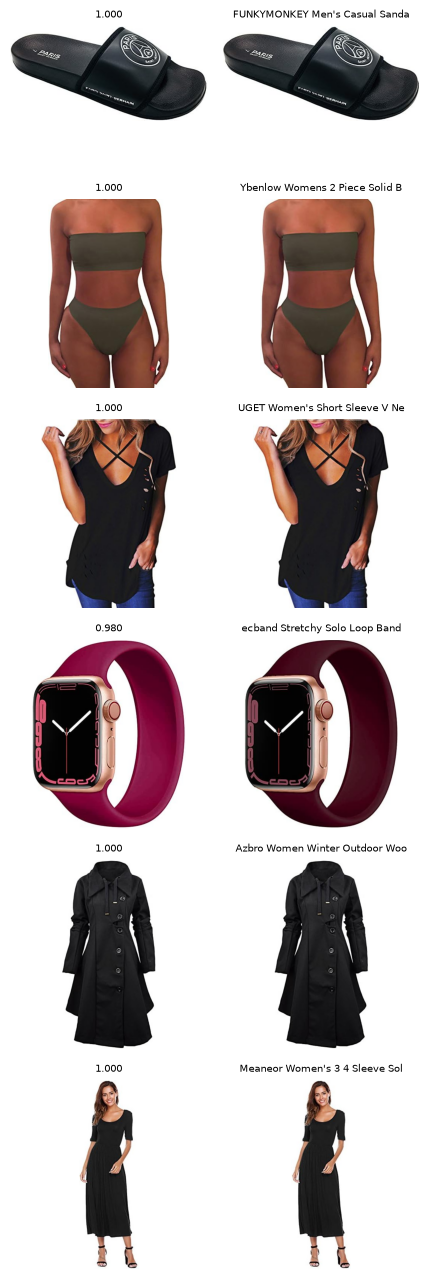

Grocery_and_Gourmet_Food


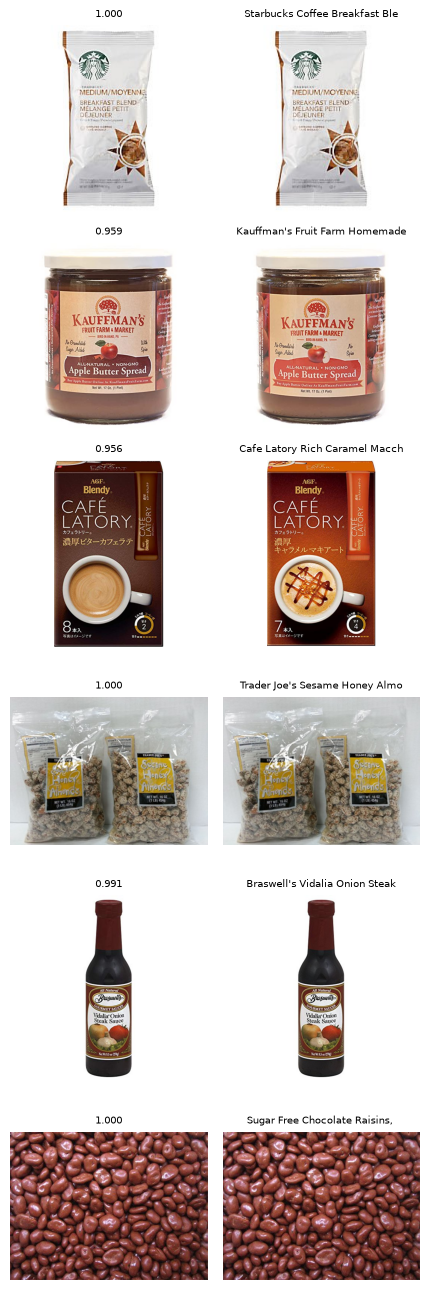

In [13]:
for category, pairs in near_dup_examples.items():
    print(category)
    items = R[category]["items"]
    show_images(
        [[items.loc[a, "main"], items.loc[b, "main"]] for a, b, _ in pairs],
        [[f"{s:.3f}", str(items.loc[b, "title"])[:30]] for _, b, s in pairs],
        size=2.2,
    )

## 4. Различимость конкретного товара

Берём главную картинку товара (MAIN) как запрос, а вторые картинки (PT01) `N_INSTANCE` товаров как галерею. Если эмбеддинг хорошо различает товары, своя PT01 будет на первом месте. Случайное угадывание дало бы top-1 = 1/`N_INSTANCE`. PT01 часто другой ракурс, деталь или фото на модели, так что это строгая проверка.

In [14]:
rows = {}
for category, r in R.items():
    inst = r["instance"]
    q = r["image_c"].loc[inst].to_numpy()
    g = r["pt01_c"].loc[inst].to_numpy()
    s = q @ g.T
    own = np.diag(s)
    rank = (s > own[:, None]).sum(axis=1) + 1
    rows[category] = {
        "товаров": len(inst),
        "top-1, %": round(100 * float((rank == 1).mean()), 1),
        "top-5, %": round(100 * float((rank <= 5).mean()), 1),
        "top-1% галереи, %": round(100 * float((rank <= len(inst) / 100).mean()), 1),
        "медианный ранг": float(np.median(rank)),
        "сходство MAIN-PT01 своего, медиана": round(float(np.median(own)), 3),
        "сходство MAIN-PT01 чужого, медиана": round(
            float(np.median(s[~np.eye(len(s), dtype=bool)])), 3
        ),
    }
instance_table = pd.DataFrame(rows).T
instance_table

,товаров,"top-1, %","top-5, %","top-1% галереи, %",медианный ранг,"сходство MAIN-PT01 своего, медиана","сходство MAIN-PT01 чужого, медиана"
Amazon_Fashion,2000.0,72.2,84.5,90.3,1.0,0.662,-0.013
Grocery_and_Gourmet_Food,2000.0,53.6,66.0,75.1,1.0,0.418,-0.008


## 5. Смысловая структура

Чистота соседей: доля из `K` ближайших соседей, у которых та же метка (тип товара или магазин), что у самого товара. Берём только метки, у которых в выборке хотя бы `MIN_LABEL` товаров (у магазинов `MIN_STORE`). «Случайно» — чистота при случайных соседях, Σp² по частотам меток.

In [15]:
def purity(x, labels, min_size):
    labels = pd.Series(labels).reset_index(drop=True)
    counts = labels.value_counts()
    keep = labels.isin(counts.index[counts >= min_size]).to_numpy()
    xs, ls = x[keep], labels[keep].to_numpy()
    _, idx = knn(xs, xs, K, same=True)
    per_item = (ls[idx] == ls[:, None]).mean(axis=1)
    freq = pd.Series(ls).value_counts(normalize=True)
    return per_item, keep, float((freq**2).sum())


rows = {}
for category, r in R.items():
    for space in ["image_c", "text_c"]:
        index = r["sample"].intersection(r[space].index)
        x = r[space].loc[index].to_numpy()
        for kind, column, min_size in [
            ("тип", "label", MIN_LABEL),
            ("магазин", "store", MIN_STORE),
        ]:
            per_item, keep, chance = purity(x, r["items"].loc[index, column], min_size)
            rows[(category, space.removesuffix("_c"), kind)] = {
                "товаров": int(keep.sum()),
                "меток": int(r["items"].loc[index[keep], column].nunique()),
                f"чистота@{K}": round(float(per_item.mean()), 3),
                "случайно": round(chance, 3),
                "во сколько раз": round(float(per_item.mean()) / chance, 1),
            }
purity_table = pd.DataFrame(rows).T
purity_table

товаров  меток  чистота@10  случайно  \
Amazon_Fashion           image тип       9730.0   25.0       0.753     0.075   
                               магазин   2033.0  202.0       0.181     0.008   
                         text  тип       9730.0   25.0       0.846     0.075   
                               магазин   2033.0  202.0       0.358     0.008   
Grocery_and_Gourmet_Food image тип       8774.0   16.0       0.571     0.241   
                               магазин   1954.0  203.0       0.331     0.010   
                         text  тип       8774.0   16.0       0.728     0.241   
                               магазин   1954.0  203.0       0.471     0.010   

                                        во сколько раз  
Amazon_Fashion           image тип                10.0  
                               магазин            21.7  
                         text  тип                11.2  
                               магазин            42.9  
Grocery_and_Gourmet_Food image тип                 2.4  
                               магазин            32.6  
                         text  тип                 3.0  
                               магазин            46.3

Метки Grocery уровня 1 крупные и разнородные: в Pantry Staples и масло, и специи, и мука. Если картинки группируют товары по более узким видам, чистота по уровню 1 это занижает. Проверка: чистота по уровню 2 (Coffee, Tea, Chips & Crisps, ...) на тех же товарах. Для сравнения берём только товары, у которых метка уровня 2 встречается в выборке хотя бы `MIN_LABEL` раз, и на них же считаем чистоту по уровню 1. Отношение к случайной чистоте у уровней разное по построению (у мелких меток выше потолок), поэтому смотрим ещё долю от потолка: (чистота − случайно) / (1 − случайно).

In [16]:
rows = {}
r = R["Grocery_and_Gourmet_Food"]
for space in ["image_c", "text_c"]:
    index = r["sample"].intersection(r[space].index)
    x = r[space].loc[index].to_numpy()
    items = r["items"].loc[index]
    per2, keep, chance2 = purity(x, items["label2"], MIN_LABEL)
    # уровень 1 на тех же товарах, без отсева редких меток
    per1, _, chance1 = purity(x[keep], items["label"][keep], 0)
    for level, per, chance, labels in [
        ("уровень 1", per1, chance1, items["label"][keep]),
        ("уровень 2", per2, chance2, items["label2"][keep]),
    ]:
        value = float(per.mean())
        rows[(space.removesuffix("_c"), level)] = {
            "товаров": int(keep.sum()),
            "меток": int(labels.nunique()),
            f"чистота@{K}": round(value, 3),
            "случайно": round(chance, 3),
            "во сколько раз": round(value / chance, 1),
            "доля от потолка": round((value - chance) / (1 - chance), 3),
        }
grocery_levels_table = pd.DataFrame(rows).T
grocery_levels_table

товаров  меток  чистота@10  случайно  во сколько раз  \
image уровень 1   8060.0   13.0       0.623     0.280             2.2   
      уровень 2   8060.0   43.0       0.428     0.079             5.4   
text  уровень 1   8060.0   13.0       0.785     0.280             2.8   
      уровень 2   8060.0   43.0       0.643     0.079             8.2   

                 доля от потолка  
image уровень 1            0.476  
      уровень 2            0.379  
text  уровень 1            0.701  
      уровень 2            0.613

UMAP выборки, цветом 8 самых частых меток (остальные серые). Слева картинки, справа названия.

/Users/alfa/Documents/Dev/hse-ai/hse-ai-26-recsys-team-120/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/alfa/Documents/Dev/hse-ai/hse-ai-26-recsys-team-120/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


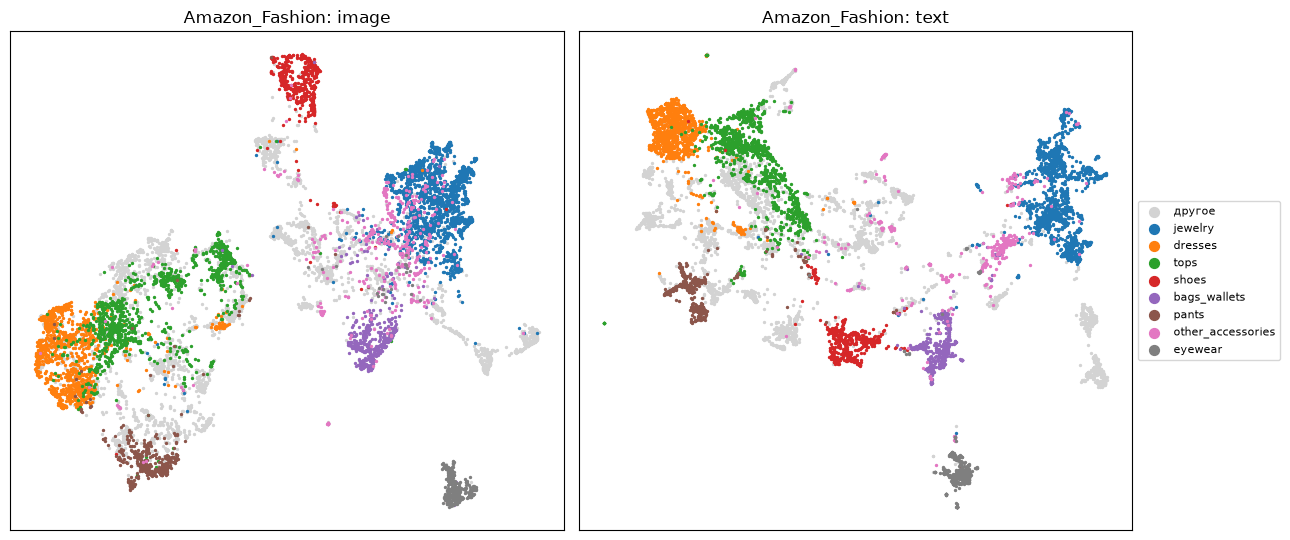

/Users/alfa/Documents/Dev/hse-ai/hse-ai-26-recsys-team-120/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/alfa/Documents/Dev/hse-ai/hse-ai-26-recsys-team-120/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


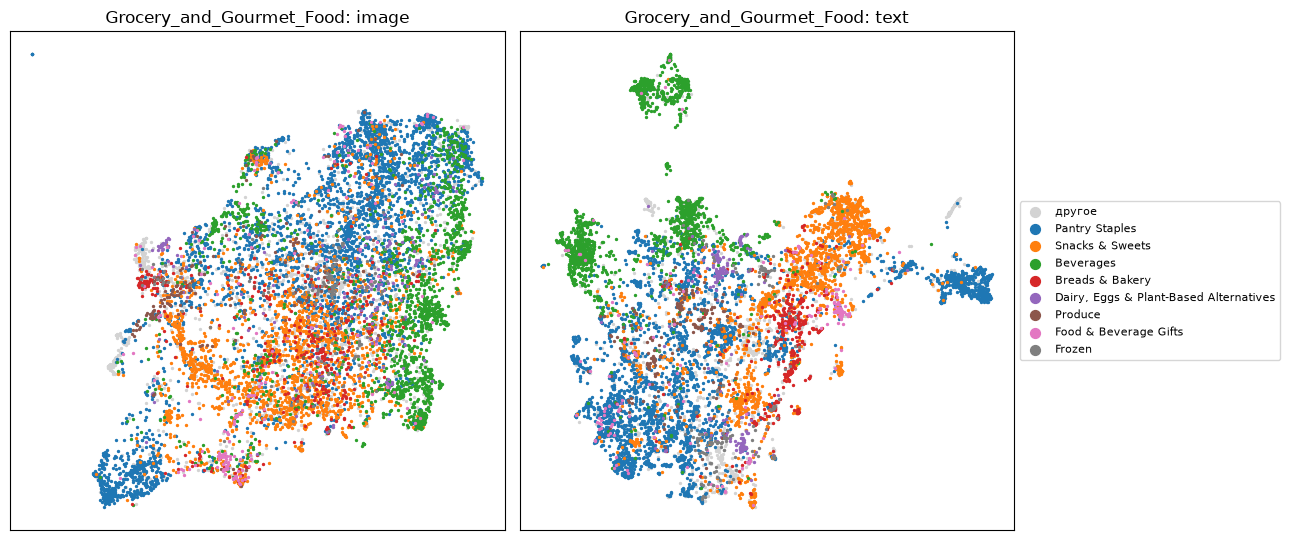

In [17]:
XY = {}  # координаты UMAP, чтобы перекрашивать без пересчёта
for category, r in R.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, space in zip(axes, ["image_c", "text_c"], strict=True):
        index = r["sample"].intersection(r[space].index)
        xy = umap.UMAP(
            n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED
        ).fit_transform(r[space].loc[index].to_numpy())
        XY[(category, space)] = (index, xy)
        labels = r["items"].loc[index, "label"].fillna("—")
        top = labels[labels != "—"].value_counts().index[:8]
        other = ~labels.isin(top).to_numpy()
        ax.scatter(xy[other, 0], xy[other, 1], s=2, c="lightgray", label="другое")
        for name in top:
            m = (labels == name).to_numpy()
            ax.scatter(xy[m, 0], xy[m, 1], s=2, label=name)
        ax.set_title(f"{category}: {space.removesuffix('_c')}")
        ax.set_xticks([])
        ax.set_yticks([])
    axes[1].legend(
        markerscale=5, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5)
    )
    plt.tight_layout()
    plt.show()

Тот же UMAP Grocery, цветом 10 самых частых меток уровня 2. Координаты те же, что выше, меняются только цвета.

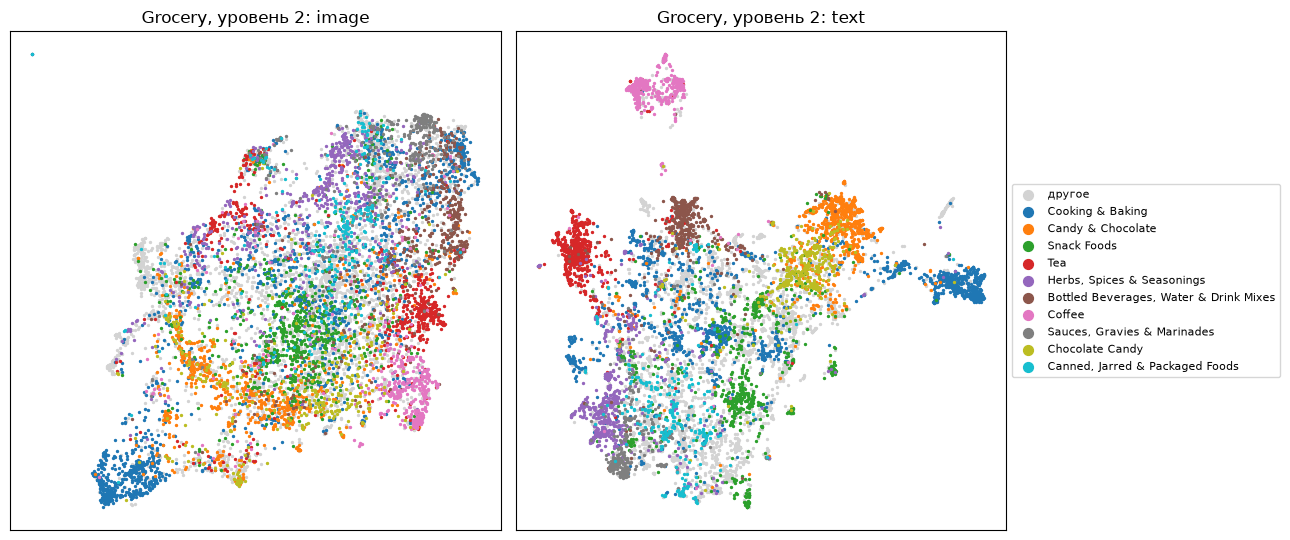

In [18]:
r = R["Grocery_and_Gourmet_Food"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, space in zip(axes, ["image_c", "text_c"], strict=True):
    index, xy = XY[("Grocery_and_Gourmet_Food", space)]
    labels = r["items"].loc[index, "label2"].fillna("—")
    top = labels[labels != "—"].value_counts().index[:10]
    other = ~labels.isin(top).to_numpy()
    ax.scatter(xy[other, 0], xy[other, 1], s=2, c="lightgray", label="другое")
    for color, name in zip([f"C{k}" for k in range(10)], top, strict=False):
        m = (labels == name).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=2, color=color, label=name)
    ax.set_title(f"Grocery, уровень 2: {space.removesuffix('_c')}")
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(markerscale=5, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

Соседи по картинке: в первом столбце случайный товар, дальше его 6 ближайших в выборке.

Amazon_Fashion


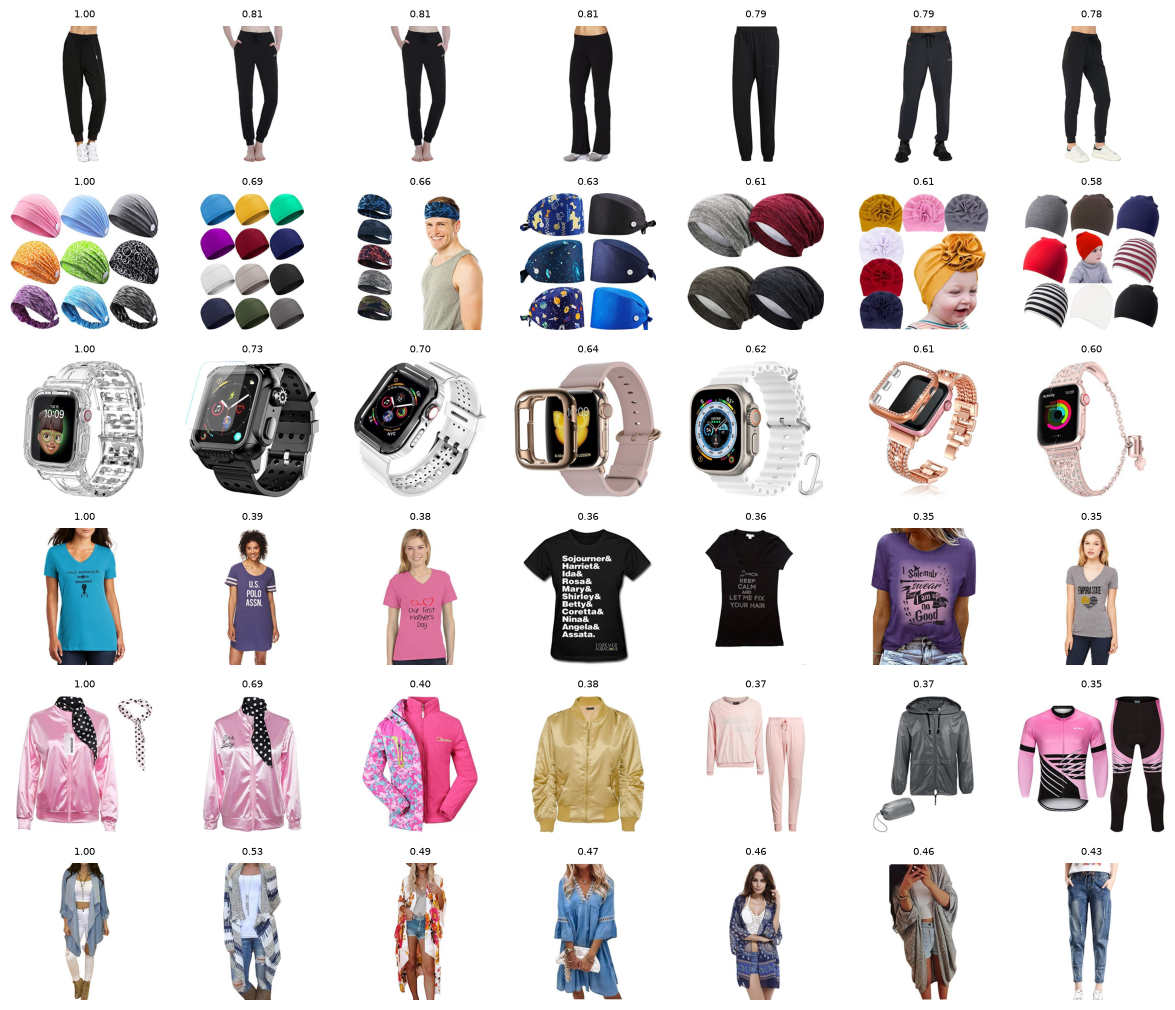

Grocery_and_Gourmet_Food


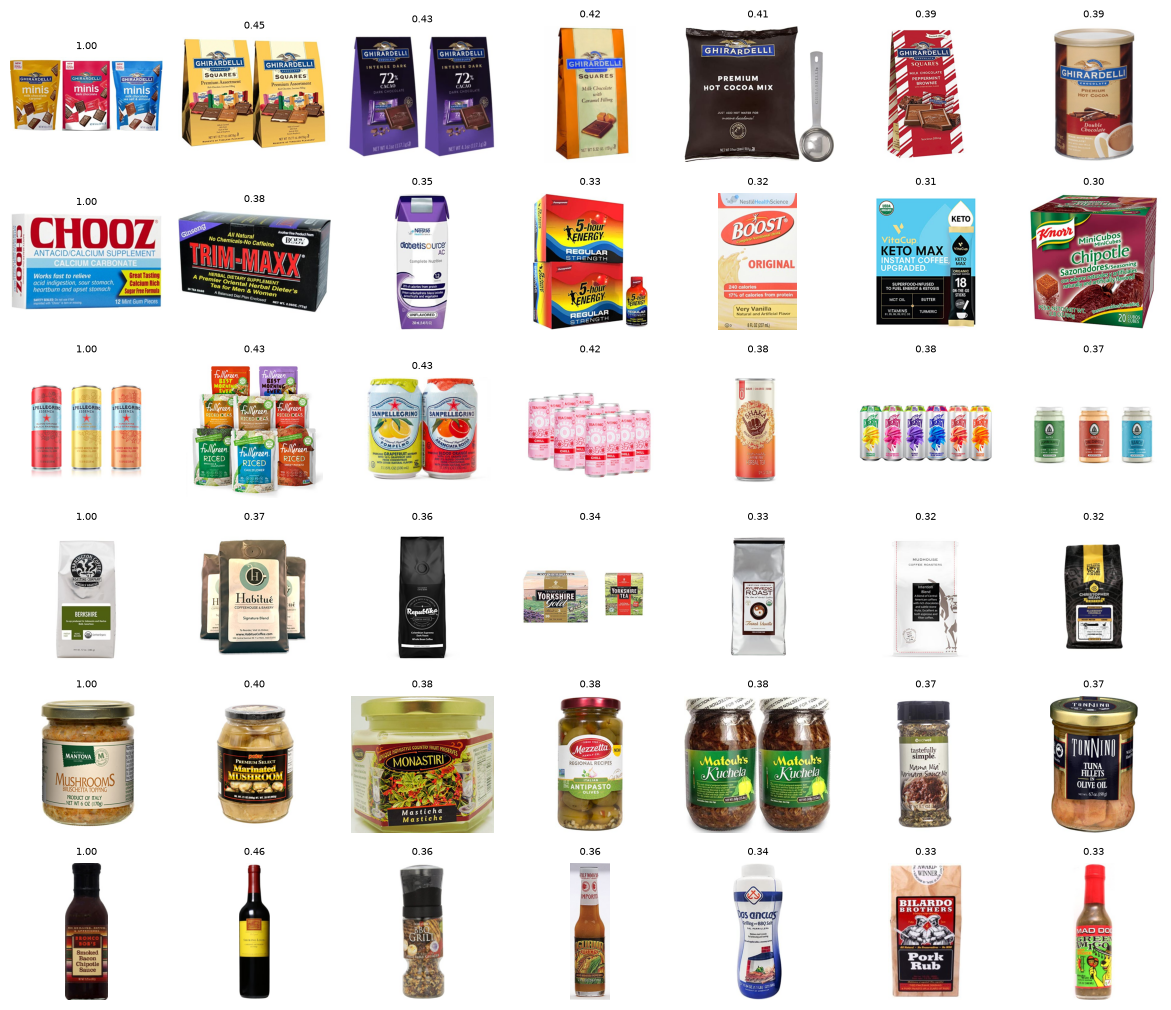

In [19]:
for category, r in R.items():
    print(category)
    index = r["sample"]
    x = matrix(r, "image_c", index)
    queries = rng.choice(len(index), size=6, replace=False)
    sims, idx = knn(x[queries], x, 7)
    urls = r["items"].loc[index, "main"].to_numpy()
    show_images(
        [list(urls[row]) for row in idx],
        [[f"{s:.2f}" for s in row] for row in sims],
    )

## 6. Хабы

В высокоразмерных пространствах некоторые точки оказываются среди ближайших соседей у очень многих других. Для рекомендаций по похожести это плохо: хаб будет рекомендоваться всем. `N_k` — сколько раз товар попал в `K` ближайших у других товаров выборки.

In [20]:
rows = {}
hubs = {}
for category, r in R.items():
    for space in ["image_c", "text_c"]:
        index = r["sample"].intersection(r[space].index)
        x = r[space].loc[index].to_numpy()
        _, idx = knn(x, x, K, same=True)
        occ = np.bincount(idx.ravel(), minlength=len(x))
        top = np.sort(occ)[::-1]
        rows[(category, space.removesuffix("_c"))] = {
            "асимметрия N_k": round(float(skew(occ)), 2),
            "max N_k": int(occ.max()),
            "% ни разу не сосед": round(100 * float((occ == 0).mean()), 1),
            "% мест у топ-1% товаров": round(
                100 * float(top[: len(x) // 100].sum() / occ.sum()), 1
            ),
        }
        if space == "image_c":
            hubs[category] = index[np.argsort(occ)[::-1][:8]]
hub_table = pd.DataFrame(rows).T
hub_table

асимметрия N_k  max N_k  % ни разу не сосед  \
Amazon_Fashion           image            1.08     50.0                 1.1   
                         text             1.34     68.0                 1.1   
Grocery_and_Gourmet_Food image            2.03     86.0                 1.5   
                         text             1.50     75.0                 1.6   

                                % мест у топ-1% товаров  
Amazon_Fashion           image                      3.4  
                         text                       3.6  
Grocery_and_Gourmet_Food image                      4.6  
                         text                       4.0

Amazon_Fashion — главные хабы по картинке


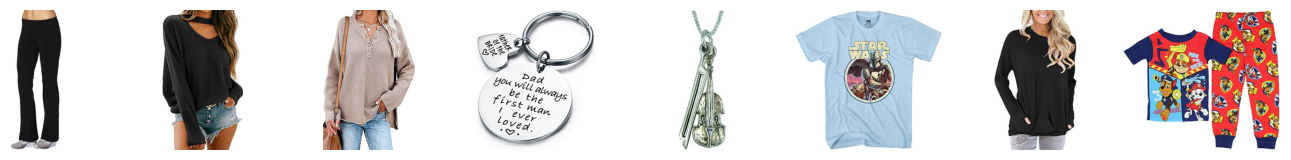

Grocery_and_Gourmet_Food — главные хабы по картинке


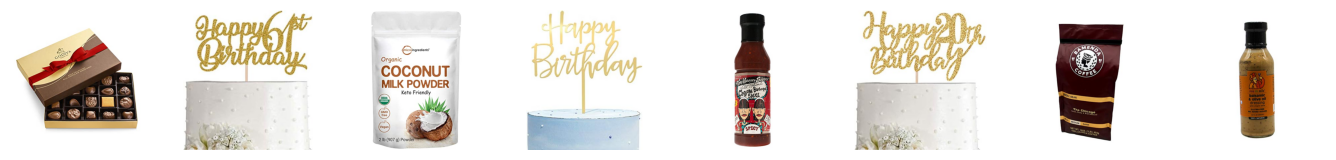

In [21]:
for category, index in hubs.items():
    print(category, "— главные хабы по картинке")
    show_images([R[category]["items"].loc[index, "main"].tolist()])

## 7. По бакетам холодности

Для холодного старта важно, отличаются ли картинки холодных товаров от тёплых. Для каждого бакета: сходство с ближайшим товаром выборки, доля почти-дубликатов, чистота соседей по типу и сходство с ближайшим тёплым (20+) товаром.

In [22]:
rows = []
for category, r in R.items():
    index = r["sample"]
    items = r["items"].loc[index]
    x = matrix(r, "image_c", index)
    raw = matrix(r, "image", index)
    nn = knn(x, x, 1, same=True)[0][:, 0]
    nn_raw = knn(raw, raw, 1, same=True)[0][:, 0]
    per_item, keep, _ = purity(x, items["label"], MIN_LABEL)
    item_purity = np.full(len(index), np.nan)
    item_purity[keep] = per_item
    warm = (items["bucket"] == "20+").to_numpy()
    s = x @ x[warm].T
    s[np.flatnonzero(warm), np.arange(warm.sum())] = -2.0  # сам себе не тёплый сосед
    frame = pd.DataFrame(
        {
            "bucket": items["bucket"].array,  # категории в порядке бакетов
            "nn": nn,
            "dup": nn_raw > NEAR_DUP,
            "purity": item_purity,
            "warm": s.max(axis=1),
        }
    )
    by = frame.groupby("bucket", observed=True)
    table = pd.DataFrame(
        {
            "товаров": by.size(),
            "сходство с ближайшим": by["nn"].median().round(3),
            "% почти-дубликатов": (100 * by["dup"].mean()).round(1),
            f"чистота@{K} по типу": by["purity"].mean().round(3),
            "сходство с ближайшим тёплым": by["warm"].median().round(3),
        }
    )
    rows.append(
        table.assign(category=category).set_index("category", append=True).swaplevel()
    )
bucket_table = pd.concat(rows)
bucket_table

товаров  сходство с ближайшим  \
category                 bucket                                  
Amazon_Fashion           0          2000                 0.639   
                         1          2000                 0.618   
                         2-4        2000                 0.627   
                         5-19       2000                 0.639   
                         20+        2000                 0.633   
Grocery_and_Gourmet_Food 0          2000                 0.480   
                         1          2000                 0.466   
                         2-4        2000                 0.467   
                         5-19       2000                 0.463   
                         20+        2000                 0.471   

                                 % почти-дубликатов  чистота@10 по типу  \
category                 bucket                                           
Amazon_Fashion           0                      1.8               0.739   
                         1                      1.2               0.750   
                         2-4                    1.4               0.757   
                         5-19                   3.2               0.768   
                         20+                    7.6               0.751   
Grocery_and_Gourmet_Food 0                      0.4               0.591   
                         1                      0.6               0.562   
                         2-4                    1.2               0.563   
                         5-19                   0.6               0.557   
                         20+                    0.6               0.583   

                                 сходство с ближайшим тёплым  
category                 bucket                               
Amazon_Fashion           0                             0.522  
                         1                             0.516  
                         2-4                           0.533  
                         5-19                          0.555  
                         20+                           0.574  
Grocery_and_Gourmet_Food 0                             0.400  
                         1                             0.388  
                         2-4                           0.387  
                         5-19                          0.387  
                         20+                           0.397

## 8. Картинки и названия

Насколько соседи по картинке совпадают с соседями по названию: доля общих среди `K` ближайших. При случайных соседях было бы около `K`/n.

In [23]:
rows = {}
for category, r in R.items():
    index = r["sample"].intersection(r["text_c"].index)
    _, by_image = knn(
        matrix(r, "image_c", index), matrix(r, "image_c", index), K, same=True
    )
    _, by_text = knn(
        matrix(r, "text_c", index), matrix(r, "text_c", index), K, same=True
    )
    overlap = [len(set(a) & set(b)) / K for a, b in zip(by_image, by_text, strict=True)]
    rows[category] = {
        "товаров": len(index),
        f"общих соседей из {K}, %": round(100 * float(np.mean(overlap)), 1),
        "случайно, %": round(100 * K / len(index), 2),
    }
overlap_table = pd.DataFrame(rows).T
overlap_table

,товаров,"общих соседей из 10, %","случайно, %"
Amazon_Fashion,9999.0,21.6,0.1
Grocery_and_Gourmet_Food,10000.0,15.8,0.1


## 9. Похожесть товаров внутри истории юзера

Для каждого юзера берём все пары товаров его истории за окно и центрированный косинус между ними, отдельно пары соседних по времени покупок. Сравниваем с:

- случайными историями той же длины, где товары взяты пропорционально популярности (см. «Выборка»);
- случайными парами товаров выборки (раздел 1).

Если у настоящих историй сходство заметно выше, юзеры выбирают похожие по картинке товары, и контентная модель может на это опереться. Широкий разброс внутри юзера (много далёких пар) — признак нескольких интересов. Средние по юзеру считаем с весом 1 на юзера, чтобы длинные истории не перевешивали.

In [24]:
def history_sims(hist, x):
    hist = hist[hist["parent_asin"].isin(x.index)]
    size = hist.groupby("user_id")["parent_asin"].transform("size")
    hist = hist[size >= 2]
    pairs, consecutive, users = [], [], []
    for user, group in hist.groupby("user_id", sort=False):
        v = x.loc[group["parent_asin"]].to_numpy()
        s = v @ v.T
        upper = s[np.triu_indices(len(v), 1)]
        pairs.append(upper)
        consecutive.append(np.diagonal(s, 1))
        users.append(
            {
                "user_id": user,
                "n": len(v),
                "mean": upper.mean(),
                "std": upper.std() if len(v) >= 3 else np.nan,
            }
        )
    return np.concatenate(pairs), np.concatenate(consecutive), pd.DataFrame(users)


rows = {}
H = {}
for category, r in R.items():
    for space in ["image_c", "text_c"]:
        x = r[space]
        real_pairs, real_consec, real_users = history_sims(r["hist"], x)
        fake_pairs, _, fake_users = history_sims(r["fake"], x)
        random_pairs = random_pair_sims(
            x.loc[r["sample"].intersection(x.index)].to_numpy()
        )
        H[(category, space)] = (real_pairs, fake_pairs, real_users, fake_users)
        name = space.removesuffix("_c")
        threshold = fake_users["mean"].quantile(0.95)
        for kind, values in [
            ("история, все пары", real_pairs),
            ("история, соседние", real_consec),
            ("случайная история", fake_pairs),
            ("случайные пары", random_pairs),
        ]:
            rows[(category, name, kind)] = describe(values)
        rows[(category, name, "среднее по юзеру")] = describe(real_users["mean"])
        rows[(category, name, "среднее по юзеру, случ.")] = describe(fake_users["mean"])
        rows[(category, name, "std по юзеру (3+)")] = describe(real_users["std"])
        rows[(category, name, "std по юзеру (3+), случ.")] = describe(fake_users["std"])
        print(
            f"{category} {name}: юзеров {len(real_users):,}, "
            f"у {(real_users['mean'] > threshold).mean():.1%} среднее выше "
            "95-го перцентиля случайных историй"
        )
history_table = pd.DataFrame(rows).T
history_table

Amazon_Fashion image: юзеров 3,000, у 26.4% среднее выше 95-го перцентиля случайных историй


Amazon_Fashion text: юзеров 3,000, у 28.3% среднее выше 95-го перцентиля случайных историй


Grocery_and_Gourmet_Food image: юзеров 3,000, у 21.2% среднее выше 95-го перцентиля случайных историй


Grocery_and_Gourmet_Food text: юзеров 3,000, у 26.9% среднее выше 95-го перцентиля случайных историй


mean    std     p5  \
Amazon_Fashion           image история, все пары         0.095  0.192 -0.135   
                               история, соседние         0.129  0.219 -0.124   
                               случайная история         0.006  0.118 -0.156   
                               случайные пары            0.001  0.116 -0.158   
                               среднее по юзеру          0.129  0.211 -0.118   
                               среднее по юзеру, случ.   0.004  0.109 -0.147   
                               std по юзеру (3+)         0.136  0.080  0.033   
                               std по юзеру (3+), случ.  0.089  0.047  0.021   
                         text  история, все пары         0.103  0.204 -0.131   
                               история, соседние         0.142  0.240 -0.126   
                               случайная история         0.008  0.120 -0.157   
                               случайные пары            0.000  0.114 -0.159   
                               среднее по юзеру          0.143  0.234 -0.122   
                               среднее по юзеру, случ.   0.008  0.113 -0.151   
                               std по юзеру (3+)         0.144  0.086  0.038   
                               std по юзеру (3+), случ.  0.090  0.047  0.024   
Grocery_and_Gourmet_Food image история, все пары         0.059  0.133 -0.104   
                               история, соседние         0.078  0.158 -0.103   
                               случайная история         0.009  0.090 -0.126   
                               случайные пары           -0.000  0.090 -0.129   
                               среднее по юзеру          0.081  0.148 -0.089   
                               среднее по юзеру, случ.   0.010  0.073 -0.104   
                               std по юзеру (3+)         0.103  0.061  0.028   
                               std по юзеру (3+), случ.  0.073  0.031  0.023   
                         text  история, все пары         0.086  0.167 -0.112   
                               история, соседние         0.120  0.204 -0.107   
                               случайная история         0.010  0.106 -0.141   
                               случайные пары            0.000  0.100 -0.141   
                               среднее по юзеру          0.125  0.191 -0.087   
                               среднее по юзеру, случ.   0.010  0.086 -0.119   
                               std по юзеру (3+)         0.129  0.077  0.032   
                               std по юзеру (3+), случ.  0.085  0.037  0.026   

                                                           p25    p50    p75  \
Amazon_Fashion           image история, все пары        -0.040  0.051  0.185   
                               история, соседние        -0.029  0.072  0.226   
                               случайная история        -0.075 -0.009  0.068   
                               случайные пары           -0.079 -0.015  0.062   
                               среднее по юзеру         -0.014  0.075  0.218   
                               среднее по юзеру, случ.  -0.068 -0.009  0.057   
                               std по юзеру (3+)         0.080  0.124  0.178   
                               std по юзеру (3+), случ.  0.057  0.086  0.115   
                         text  история, все пары        -0.034  0.054  0.187   
                               история, соседние        -0.024  0.076  0.243   
                               случайная история        -0.074 -0.008  0.070   
                               случайные пары           -0.078 -0.014  0.061   
                               среднее по юзеру         -0.015  0.078  0.234   
                               среднее по юзеру, случ.  -0.064 -0.004  0.065   
                               std по юзеру (3+)         0.084  0.133  0.176   
                               std по юзеру (3+), случ.  0.055  0.089  0.115   
Grocery_and_Gourmet_Food image история, все пары        -

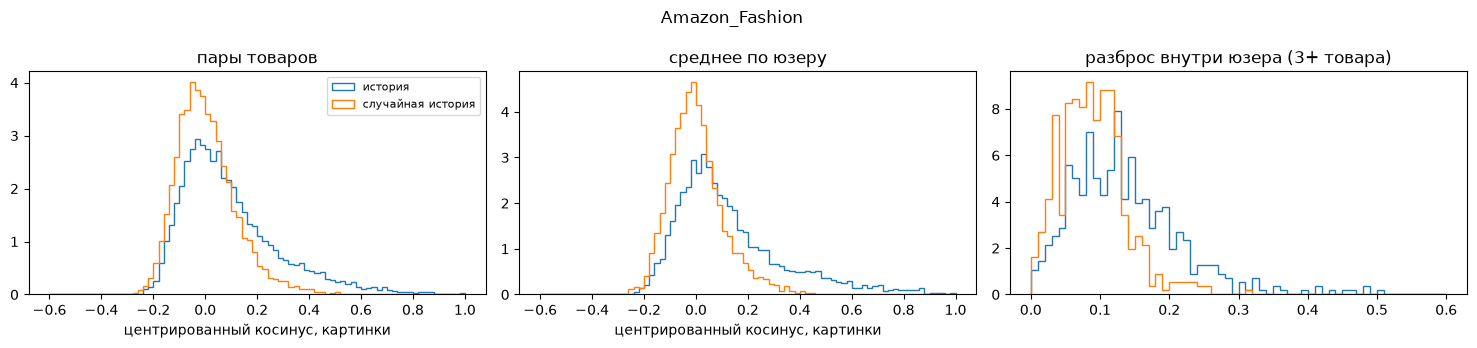

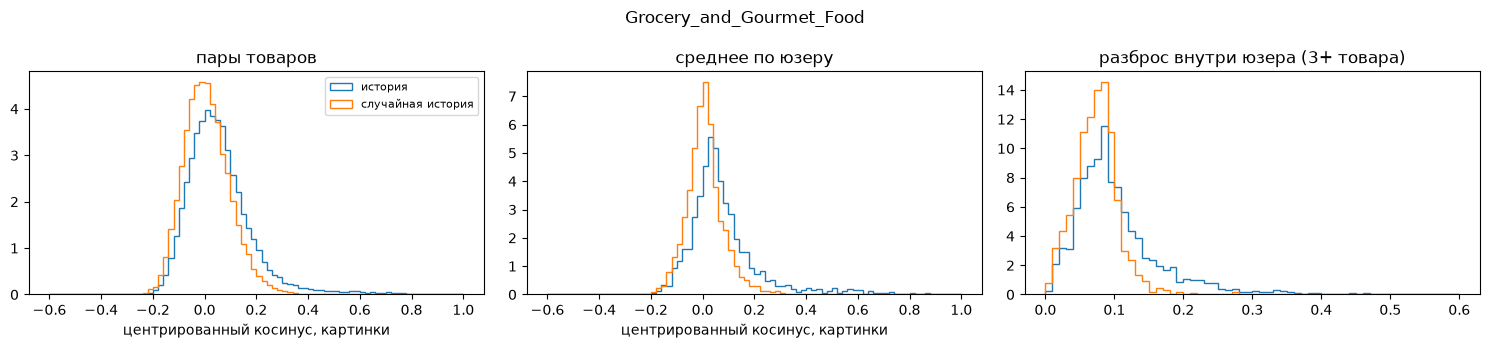

In [25]:
for category in R:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    real_pairs, fake_pairs, real_users, fake_users = H[(category, "image_c")]
    bins = np.linspace(-0.6, 1, 81)
    axes[0].hist(real_pairs, bins=bins, density=True, histtype="step", label="история")
    axes[0].hist(
        fake_pairs, bins=bins, density=True, histtype="step", label="случайная история"
    )
    axes[0].set_title("пары товаров")
    axes[1].hist(
        real_users["mean"], bins=bins, density=True, histtype="step", label="история"
    )
    axes[1].hist(
        fake_users["mean"],
        bins=bins,
        density=True,
        histtype="step",
        label="случайная история",
    )
    axes[1].set_title("среднее по юзеру")
    std_bins = np.linspace(0, 0.6, 61)
    axes[2].hist(
        real_users["std"].dropna(),
        bins=std_bins,
        density=True,
        histtype="step",
        label="история",
    )
    axes[2].hist(
        fake_users["std"].dropna(),
        bins=std_bins,
        density=True,
        histtype="step",
        label="случайная история",
    )
    axes[2].set_title("разброс внутри юзера (3+ товара)")
    for ax in axes[:2]:
        ax.set_xlabel("центрированный косинус, картинки")
    axes[0].legend(fontsize=8)
    fig.suptitle(category)
    plt.tight_layout()
    plt.show()

Сходство растёт с длиной истории или нет: среднее по юзеру в зависимости от числа товаров.

In [26]:
rows = []
for category in R:
    _, _, real_users, fake_users = H[(category, "image_c")]
    bins, labels = [1, 2, 4, 9, float("inf")], ["2", "3-4", "5-9", "10+"]
    real = real_users.groupby(
        pd.cut(real_users["n"], bins, labels=labels), observed=True
    )["mean"]
    fake = fake_users.groupby(
        pd.cut(fake_users["n"], bins, labels=labels), observed=True
    )["mean"]
    table = pd.DataFrame(
        {
            "юзеров": real.size(),
            "история": real.median().round(3),
            "случайная история": fake.median().round(3),
        }
    )
    rows.append(
        table.assign(category=category).set_index("category", append=True).swaplevel()
    )
by_length_table = pd.concat(rows)
by_length_table

юзеров  история  случайная история
category                 n                                      
Amazon_Fashion           2      2443    0.070             -0.014
                         3-4     425    0.104             -0.004
                         5-9      88    0.068              0.001
                         10+      44    0.056              0.004
Grocery_and_Gourmet_Food 2      1714    0.048              0.004
                         3-4     836    0.052              0.004
                         5-9     354    0.049              0.006
                         10+      96    0.053              0.007

## Сохраняем таблицы

In [27]:
REPORTS = Path("../reports")
tables = {
    "pairs": pair_table,
    "pca": pca_table,
    "near_dup": near_dup_table,
    "instance": instance_table,
    "purity": purity_table,
    "purity_grocery_levels": grocery_levels_table,
    "hubs": hub_table,
    "buckets": bucket_table,
    "overlap": overlap_table,
    "history": history_table,
    "history_by_length": by_length_table,
}
for name, table in tables.items():
    table.to_csv(REPORTS / f"eda_images_{name}.csv")

## Итог

**Картинки не «все одинаковые».** Сырой косинус случайных пар 0.40 ± 0.11 у Fashion и 0.30 ± 0.09 у Grocery: это обычный для CLIP узкий конус, а не похожесть товаров. После центрирования у случайной пары около 0. Пространство не схлопнуто: 50% дисперсии приходится на 36 (Fashion) и 59 (Grocery) компонент из 512, participation ratio 79 и 121. У эмбеддингов названий так же или меньше.

**Конкретный товар различим.** По главной картинке (MAIN) вторая картинка того же товара (PT01) стоит первой среди 2000 у 72% товаров Fashion и 54% Grocery, при случайном выборе было бы 0.05%. Медианный ранг 1.

**Есть смысловая структура.** Из 10 соседей по картинке того же типа 0.75 у Fashion (случайно 0.075, 25 типов) и 0.57 у Grocery (случайно 0.24). Названия группируют по типу лучше: 0.85 и 0.73. У Fashion часть этого перевеса от того, что типы размечены по названиям. Магазин тоже узнаётся: 0.18 и 0.33 при случайных 0.01. Соседи по картинке и по названию совпадают только на 22% и 16%, то есть картинка не повторяет название, а добавляет своё.

**Главный риск для Fashion — дубликаты.** У 32% товаров Fashion главная картинка (тот же URL) совпадает с картинкой другого товара, у Grocery у 9%. В выборке Fashion у 2.4% товаров есть сосед с косинусом выше 0.99, среди популярных (20+) почти-дубликатов 7.6%. Это один и тот же товар под разными `parent_asin` (разные продавцы, варианты). По картинке модель их не различит, а при оценке рекомендация дубля засчитается как промах. Стоит решить, склеивать ли такие товары.

**Хабов немного.** Асимметрия `N_k` 1–2, топ-1% товаров занимает 3–5% мест среди соседей. В Grocery главные хабы — топперы для тортов и подарочные наборы.

**Холодные товары по картинке не хуже тёплых.** Сходство с ближайшим, чистота соседей по типу и сходство с ближайшим тёплым (20+) товаром почти одинаковы во всех бакетах. Выделяются только популярные товары Fashion: у них больше почти-дубликатов.

**Истории юзеров.** Товары внутри истории похожи больше, чем в случайной истории той же популярности. Среднее по юзеру (центрированный косинус картинок) 0.13 против 0.00 у Fashion и 0.08 против 0.01 у Grocery. Соседние по времени покупки похожи сильнее, чем все пары: 0.13 и 0.08 против 0.10 и 0.06. Но сдвиг небольшой и неравномерный: медиана по юзерам 0.075 и 0.05, длинный хвост очень похожих пар, и только у 26% (Fashion) и 21% (Grocery) юзеров среднее выше 95-го перцентиля случайных историй. Разброс внутри юзера больше, чем у случайной истории (std 0.14 против 0.09 у Fashion), то есть у многих юзеров есть и очень похожие, и совсем разные товары, похоже на несколько интересов. Вывод: по похожести картинок хорошо описывается примерно четверть юзеров, для остальных нужна коллаборативная часть. Названия дают сигнал не слабее картинок, у Grocery сильнее (0.13 против 0.08).

**Ограничения.** Хвост очень похожих пар в историях может частично объясняться дубликатами: юзер купил один и тот же товар под разными `parent_asin`. Типы товаров Fashion размечены LLM по названиям: на справочнике Amazon совпадают с каталогом у 87.5% товаров, на самих товарах Fashion точность не проверена. Из-за разметки по названиям сравнение картинок и названий у Fashion смещено в пользу названий. У половины юзеров в истории всего 2 товара. Все выводы сделаны на одной модели (CLIP ViT-B/32).